# Chess dataset: balance, diversity and training decisions

**Question: what does this dataset cover, and which experiments are worth running next?**

Run all cells in order. This notebook reads the frozen **chess-v1 train and validation**
files. Figures and numerical findings stay in this notebook; conclusions are documented in `docs/datasets.md`.
It does not modify datasets or train a model. Install `notebooks/requirements.txt` first.
The reserved test file is not opened: choose models using validation, then evaluate
on test after freezing the choices. See [preparation](prepare_dataset.ipynb) to recreate
local data and the [dataset guide](../docs/datasets.md) for reference recreation.


In [1]:
from pathlib import Path
import sys, json
import matplotlib.pyplot as plt

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'scripts' / 'analyze_dataset.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open from the MyTorch project or its notebooks/ folder')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from scripts.analyze_dataset import LABELS, PIECES, analyze_split, input_overlap, shortcut_baselines

MANIFEST = ROOT / 'dataset/manifests/chess-v1.json'
manifest = json.loads(MANIFEST.read_text())
DATA = ROOT / manifest['storage'] / 'splits'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
COLORS = ['#3178b8', '#d78325', '#369264']

def show_figure(fig):
    plt.show()
    plt.close(fig)

print('Reference:', manifest['name'])
print('Read: train.txt and validation.txt only')


Reference: chess-v1
Read: train.txt and validation.txt only


## 1. Identity and integrity

Read all rows, validate their format, hash each file and check the frozen manifest.
The overlap key is **piece placement + side to move + en passant**, matching the
777 model inputs. Castling rights and move counters do not distinguish network
inputs. Repeated rows remain in the statistics so that training oversampling is
visible. Conflicting labels for the same input are reported separately.


In [2]:
splits, keys = {}, {}
for name in ('train', 'validation'):
    splits[name], keys[name] = analyze_split(DATA / f'{name}.txt')
    expected = manifest['artifacts'][name]['sha256']
    if splits[name]['sha256'] != expected:
        raise ValueError(f'{name}: SHA-256 differs from the frozen manifest; recreate chess-v1')
    s = splits[name]
    print(f"{name:12} rows={s['rows']:,} unique inputs={s['unique_inputs']:,} "
          f"repeats={s['repeated_input_rows']:,} conflicts={s['conflicting_inputs']:,}")
overlap = input_overlap(keys['train'], keys['validation'])
print('Train/validation input overlap:', overlap)
if overlap['shared_inputs'] or any(s['conflicting_inputs'] for s in splits.values()):
    raise ValueError('Resolve overlapping inputs or conflicting labels before comparing models')
del keys  # large identity maps are no longer needed


train        rows=572,445 unique inputs=572,445 repeats=0 conflicts=0
validation   rows=71,555 unique inputs=71,555 repeats=0 conflicts=0
Train/validation input overlap: {'shared_inputs': 0, 'different_labels': 0}


## 2. Class representation

Compare **proportions**, not raw train/validation totals. A majority-class baseline
is fitted on train below. A moderate class imbalance alone is not a reason to
oversample: consider per-class recall and macro-F1 as well as accuracy.


train        Nothing      238,051  41.58%
train        Check        198,507  34.68%
train        Checkmate    135,887  23.74%
validation   Nothing       29,756  41.58%
validation   Check         24,813  34.68%
validation   Checkmate     16,986  23.74%


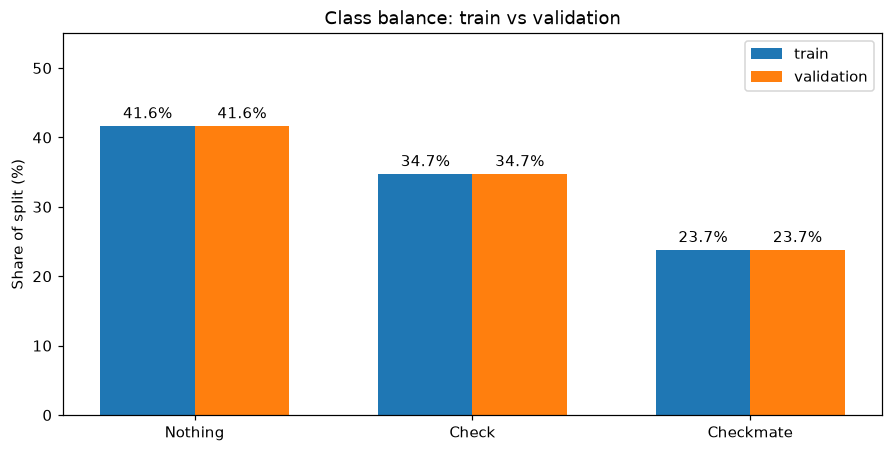

In [3]:
fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
for offset, (name, summary) in enumerate(splits.items()):
    values = [100 * summary['classes'][label]['rows'] / summary['rows'] for label in LABELS]
    bars = ax.bar([i + (offset - .5) * .34 for i in range(3)], values, .34, label=name)
    ax.bar_label(bars, fmt='%.1f%%', padding=3)
    for label in LABELS:
        n = summary['classes'][label]['rows']
        print(f'{name:12} {label:10} {n:>9,} {n / summary["rows"]:7.2%}')
ax.set(xticks=range(3), xticklabels=LABELS, ylabel='Share of split (%)',
       title='Class balance: train vs validation', ylim=(0, 55))
ax.legend()
show_figure(fig)


## 3. Material diversity and split shift

Total occupied squares describe material density, not legal game phase. Curves
are normalized **within each class and split**. Peaks or gaps can reveal limited
sampling, even when class totals look balanced. Total variation (TV) is half the
sum of absolute probability differences: 0 means identical distributions and 1
means disjoint distributions. It is descriptive, not a significance test.


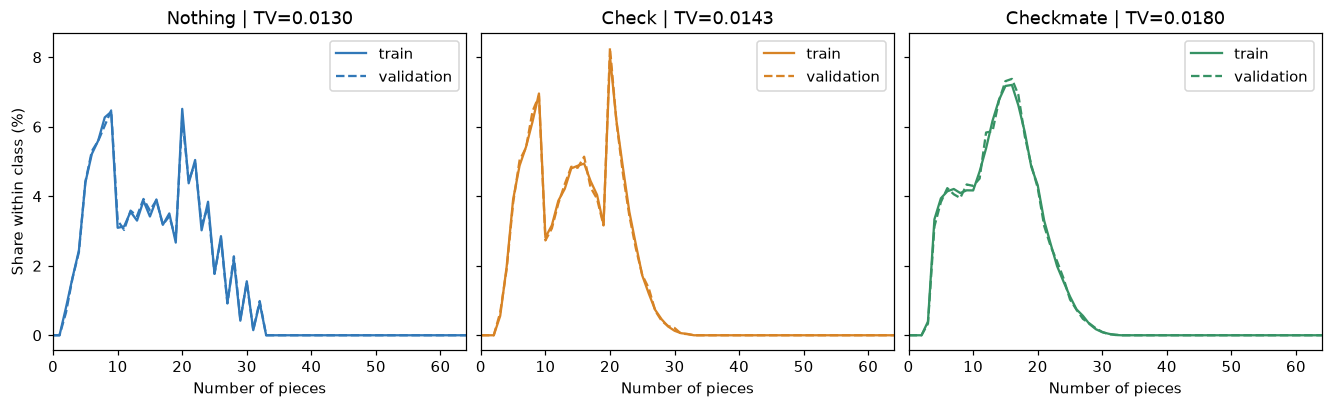

Nothing most frequent piece counts: [('20', 15508), ('9', 15306), ('8', 14921), ('7', 13347), ('6', 12419)]
Check most frequent piece counts: [('20', 15940), ('9', 13808), ('21', 12258), ('8', 12192), ('7', 10763)]
Checkmate most frequent piece counts: [('16', 9788), ('15', 9747), ('14', 9204), ('17', 8990), ('13', 8385)]


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout='constrained', sharey=True)
material_tv = {}
for ax, label, color in zip(axes, LABELS, COLORS):
    distributions = {}
    for name, summary in splits.items():
        stats = summary['classes'][label]
        values = [stats['piece_count'].get(str(n), 0) / stats['rows'] if stats['rows'] else 0
                  for n in range(65)]
        distributions[name] = values
        ax.plot(range(65), [100 * x for x in values], color=color,
                linestyle='-' if name == 'train' else '--', label=name)
    material_tv[label] = .5 * sum(abs(a - b) for a, b in
                                zip(distributions['train'], distributions['validation']))
    ax.set(title=f'{label} | TV={material_tv[label]:.4f}', xlabel='Number of pieces', xlim=(0, 64))
    ax.legend()
axes[0].set_ylabel('Share within class (%)')
show_figure(fig)
for label in LABELS:
    counts = splits['train']['classes'][label]['piece_count']
    modes = sorted(counts.items(), key=lambda item: (-item[1], int(item[0])))[:5]
    print(label, 'most frequent piece counts:', modes)


## 4. Side to move and piece types

White/Black here means **the player to move**, not the winner or checked king.
Piece frequencies are average pieces per position, separated by piece color.
These are descriptive associations: they do not establish why a model errs.


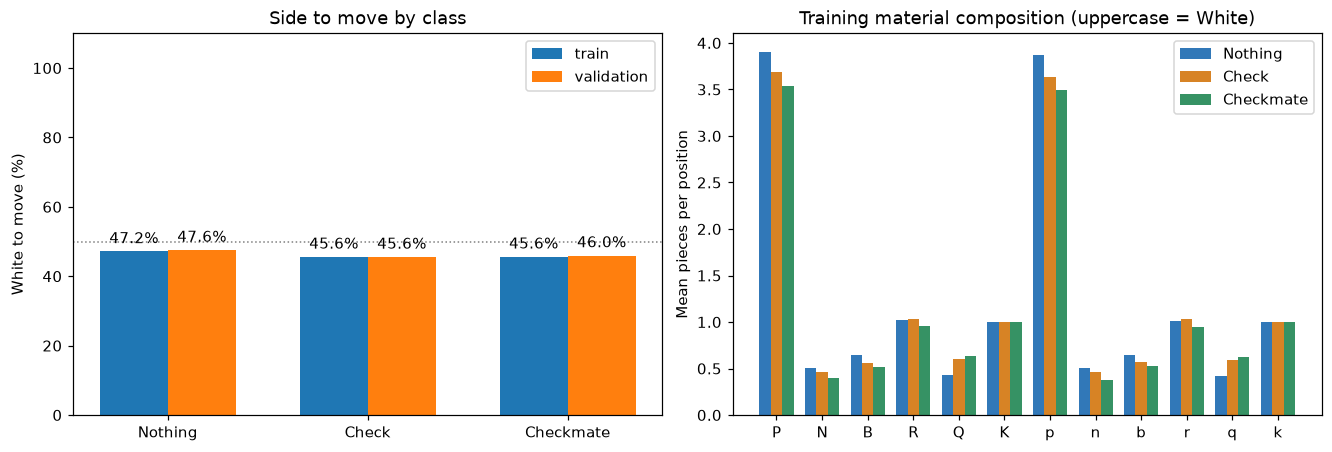

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for offset, (name, summary) in enumerate(splits.items()):
    values = [100 * summary['classes'][label]['turn'].get('w', 0)
              / summary['classes'][label]['rows'] if summary['classes'][label]['rows'] else 0
              for label in LABELS]
    bars = axes[0].bar([i + (offset - .5) * .34 for i in range(3)], values, .34, label=name)
    axes[0].bar_label(bars, fmt='%.1f%%', padding=3)
axes[0].axhline(50, color='gray', linewidth=1, linestyle=':')
axes[0].set(xticks=range(3), xticklabels=LABELS, ylim=(0, 110),
            ylabel='White to move (%)', title='Side to move by class')
axes[0].legend()
for offset, (label, color) in enumerate(zip(LABELS, COLORS)):
    stats = splits['train']['classes'][label]
    values = [stats['pieces'].get(piece, 0) / stats['rows'] if stats['rows'] else 0 for piece in PIECES]
    axes[1].bar([i + (offset - 1) * .25 for i in range(12)], values, .25, label=label, color=color)
axes[1].set(xticks=range(12), xticklabels=list(PIECES), ylabel='Mean pieces per position',
            title='Training material composition (uppercase = White)')
axes[1].legend()
show_figure(fig)


## 5. Board coverage and structural limitations

Each heatmap shows the percentage of training positions in a class that occupy
a square, summed over piece types. The orientation matches FEN: a8 at top left.
A rarely occupied square or a rare piece-square combination may be poorly learned.
Missing/multiple kings are a structural warning only; these checks **do not validate
chess legality or check/checkmate labels**. Source filenames do not establish the
actual generation method or representativeness of real games.


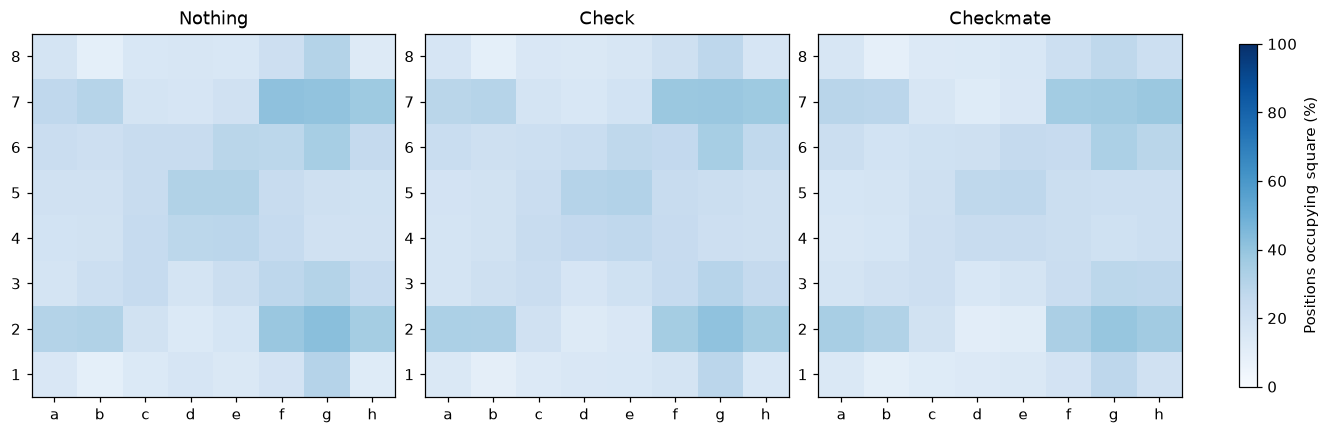

train        Nothing   : king-count anomalies=0, en passant declared=126
train        Check     : king-count anomalies=0, en passant declared=38
train        Checkmate : king-count anomalies=0, en passant declared=0
validation   Nothing   : king-count anomalies=0, en passant declared=14
validation   Check     : king-count anomalies=0, en passant declared=7
validation   Checkmate : king-count anomalies=0, en passant declared=0
Observed piece-square combinations out of 768 (not all are legal): {'Nothing': 736, 'Check': 736, 'Checkmate': 736}


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout='constrained')
coverage = {}
for ax, label in zip(axes, LABELS):
    stats = splits['train']['classes'][label]
    values = [100 * sum(stats['square_piece_counts'][piece][square] for piece in PIECES)
              / stats['rows'] if stats['rows'] else 0 for square in range(64)]
    coverage[label] = sum(n > 0 for piece in PIECES for n in stats['square_piece_counts'][piece])
    heat = ax.imshow([values[i:i+8] for i in range(0, 64, 8)], vmin=0, vmax=100, cmap='Blues')
    ax.set(xticks=range(8), xticklabels=list('abcdefgh'), yticks=range(8),
           yticklabels=list('87654321'), title=label)
fig.colorbar(heat, ax=axes, label='Positions occupying square (%)', shrink=.8)
show_figure(fig)
for name, summary in splits.items():
    for label in LABELS:
        stats = summary['classes'][label]
        ep = stats['rows'] - stats['en_passant'].get('-', 0)
        print(f"{name:12} {label:10}: king-count anomalies={stats['king_count_anomalies']:,}, "
              f'en passant declared={ep:,}')
print('Observed piece-square combinations out of 768 (not all are legal):', coverage)


## 6. Can simple dataset shortcuts predict the label?

Both rules learn their label choices **only from training**. The first always
predicts its majority class. The second predicts a majority label for each
(side to move, piece count) group, falling back to the global training majority
for unseen groups. Macro-F1 always includes all three classes.

High shortcut performance suggests sampling patterns that a neural model could
exploit; it does not prove that any particular network uses them. This is a
reference diagnostic, not an alternative to the required supervised neural model.


train_majority           validation accuracy=41.58% macro-F1=0.1958
turn_and_piece_count     validation accuracy=42.91% macro-F1=0.3793
Fallback rows: 0


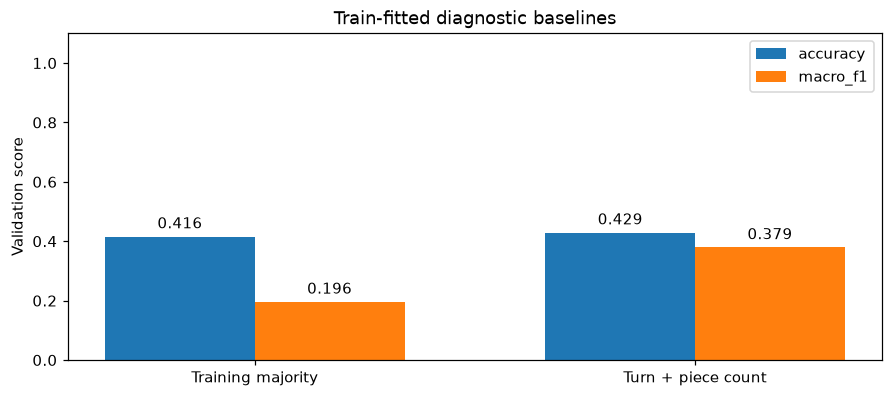

In [7]:
baselines = shortcut_baselines(splits['train'], splits['validation'])
for name in ('train_majority', 'turn_and_piece_count'):
    score = baselines[name]
    print(f"{name:24} validation accuracy={score['accuracy']:.2%} macro-F1={score['macro_f1']:.4f}")
print('Fallback rows:', baselines['unseen_validation_group_rows'])
fig, ax = plt.subplots(figsize=(8, 3.5), layout='constrained')
names = ('train_majority', 'turn_and_piece_count')
for offset, metric in enumerate(('accuracy', 'macro_f1')):
    bars = ax.bar([i + (offset - .5) * .34 for i in range(2)],
                  [baselines[name][metric] for name in names], .34, label=metric)
    ax.bar_label(bars, fmt='%.3f', padding=3)
ax.set(xticks=range(2), xticklabels=['Training majority', 'Turn + piece count'],
       ylim=(0, 1.1), ylabel='Validation score', title='Train-fitted diagnostic baselines')
ax.legend()
show_figure(fig)


## 7. Interpret findings and decide the next experiment

The cells above retain the counts, dataset identity, integrity checks and baseline
scores. Figures stay in this notebook; document useful conclusions in `docs/datasets.md`.

Use the observations to fill this decision log before running more experiments:

| Observation | Experiment | Evidence required to keep it |
| --- | --- | --- |
| Weak minority-class recall, alongside unequal training support | Compare original vs balanced **training only** | Better validation macro-F1/recall at a declared time budget |
| Sparse material/square coverage | Inspect validation errors in those groups; consider justified training data enrichment | Improvement on the same validation split, without duplicate leakage |
| Strong turn/material shortcut | Inspect errors across material/turn groups | Improvement across groups, not only aggregate accuracy |
| Train and validation losses still decreasing | Extend the baseline with early stopping | Validation improvement and measured runtime |
| Training improves while validation worsens | Stop at the best validation checkpoint; compare a smaller model | Reduced gap without losing validation quality |

Do not select an experiment using the reserved test set. Class balancing is a
hypothesis to measure, not an automatic fix. See [evaluation.ipynb](evaluation.ipynb)
for the actual model's class scores and confusion matrix.


In [8]:
train_counts = [splits['train']['classes'][label]['rows'] for label in LABELS]
print(f'Training largest/smallest class ratio: {max(train_counts) / min(train_counts):.2f}x')
print('Compare these findings with validation errors before deciding to balance training.')


Training largest/smallest class ratio: 1.75x
Compare these findings with validation errors before deciding to balance training.


## Observed chess-v1 findings (train/validation snapshot)

- **Class support:** Nothing 41.58%, Check 34.68%, Checkmate 23.74%; largest/smallest training ratio 1.75×. Check is not the rarest class, so weak Check recall alone does not establish a lack of examples.
- **Integrity:** no repeated model inputs, conflicting labels or train/validation input overlap in the inspected files. Both hashes match the frozen reference.
- **Split similarity:** piece-count TV is 0.0130 for Nothing, 0.0143 for Check and 0.0180 for Checkmate. These measured distributions are close; this does not prove that the data represents real games.
- **Simple shortcuts:** training-majority validation accuracy is 41.58% (macro-F1 0.1958). Turn plus piece count reaches 42.91% (macro-F1 0.3793). These two simple rules do not explain the neural baseline's 72.73% validation accuracy; richer shortcuts could still exist.
- **Structural checks:** every inspected position has one king per side. En passant is declared in only 164 training positions and 21 validation positions, with none labeled Checkmate. Legal move availability and label correctness remain unaudited.

**Recommended next experiment:** extend the current neural baseline with the same settings and early stopping, then compare learning rate/activation candidates. Keep balancing as a controlled alternative if per-class validation errors justify it; do not make it the default just because class totals differ. Inspect material/turn groups when investigating Check errors.

These observations apply to the frozen dataset version checked at the start of this notebook. Revisit them after changing dataset versions. The neural baseline figures come from the separately recorded v0.1.0 validation evaluation, not from predictions run in this notebook.
